In [ ]:
import numpy as np
import pandas as pd
import tensorflow as tf
from keras.models import Sequential
from keras.layers import Dense
from keras.optimizers import Adam
from keras.layers import Dropout
from keras import regularizers
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler,MinMaxScaler
from tensorflow.keras.callbacks import EarlyStopping # type: ignore
from tensorflow.keras.utils import to_categorical
from sklearn.preprocessing import LabelEncoder

In [ ]:
file_path = '../Dataset Creation/mold_dataset_balanced.csv'
dataset = pd.read_csv(file_path)

In [ ]:
X = dataset.drop(columns=['mold_risk_category','timestamp', 'date'])
y = dataset['mold_risk_category']

In [ ]:
# Round the specified columns in the dataset to 2 decimal points
cols_to_round = ['temperature', 'humidity', 'light', 'pressure']
dataset[cols_to_round] = dataset[cols_to_round].round(2)

In [ ]:
# Create a label encoder and transform string labels to integers
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

# Get number of classes and print the mapping of labels
num_classes = len(np.unique(y_encoded))
print(f"Number of classes: {num_classes}")
print(f"Class labels mapping: {dict(zip(label_encoder.classes_, range(num_classes)))}")

# Convert class vector to binary class matrices (one-hot encoding)
y_categorical = to_categorical(y_encoded, num_classes=num_classes)

# Scale features before train_test_split
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y_categorical, test_size=0.2, random_state=42, stratify=y_encoded
)

Number of classes: 3
Class labels mapping: {'High': 0, 'Low': 1, 'Moderate': 2}


In [ ]:
# Reduce layers and units
model = tf.keras.models.Sequential([
    tf.keras.layers.Dense(16, activation='relu', input_shape=(X_train.shape[1],),kernel_regularizer=tf.keras.regularizers.l2(0.5)),
    tf.keras.layers.Dropout(0.5),
    tf.keras.layers.Dense(8, activation='relu',kernel_regularizer=tf.keras.regularizers.l2(0.05)),
    tf.keras.layers.Dense(len(y.unique()), activation='softmax')
])

c:\Users\vivek\anaconda3\envs\RTX-4070\lib\site-packages\keras\src\layers\core\dense.py:92: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
model.summary()

Model: "sequential_16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_48 (Dense)                │ (None, 16)             │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_16 (Dropout)            │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_49 (Dense)                │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_50 (Dense)                │ (None, 3)              │            27 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 243 (972.00 B)

 Trainable params: 243 (972.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:
adam = Adam(learning_rate=0.0001)

In [ ]:
model.compile(optimizer=adam, loss='categorical_crossentropy', metrics=['accuracy'])

In [ ]:
early_stopping = EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True)

In [ ]:
history = model.fit(X_train, y_train,epochs=50,batch_size=64,validation_data=(X_test, y_test),verbose=1,callbacks=[early_stopping])

Epoch 1/50
2632/2632 ━━━━━━━━━━━━━━━━━━━━ 9s 3ms/step - accuracy: 0.4715 - loss: 3.0598 - val_accuracy: 0.8139 - val_loss: 1.6148
Epoch 2/50
2632/2632 ━━━━━━━━━━━━━━━━━━━━ 8s 3ms/step - accuracy: 0.6979 - loss: 1.1521 - val_accuracy: 0.9122 - val_loss: 0.7910
Epoch 3/50
2632/2632 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.7985 - loss: 0.7706 - val_accuracy: 0.9611 - val_loss: 0.6277
Epoch 4/50
2632/2632 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.8312 - loss: 0.6864 - val_accuracy: 0.9748 - val_loss: 0.5576
Epoch 5/50
2632/2632 ━━━━━━━━━━━━━━━━━━━━ 6s 2ms/step - accuracy: 0.8419 - loss: 0.6381 - val_accuracy: 0.9799 - val_loss: 0.5097
Epoch 6/50
2632/2632 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.8786 - loss: 0.6014 - val_accuracy: 0.9820 - val_loss: 0.4730
Epoch 7/50
2632/2632 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - accuracy: 0.8870 - loss: 0.5753 - val_accuracy: 0.9837 - val_loss: 0.4453
Epoch 8/50
2632/2632 ━━━━━━━━━━━━━━━━━━━━ 7s 2ms/step - accuracy: 0.8942 - loss: 0.5502 - 

In [ ]:
test_loss, test_accuracy = model.evaluate(X_test, y_test)
print(f"Test Loss: {test_loss:.4f}, Test Accuracy: {test_accuracy:.4f}")

1316/1316 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9933 - loss: 0.2183
Test Loss: 0.2183, Test Accuracy: 0.9933


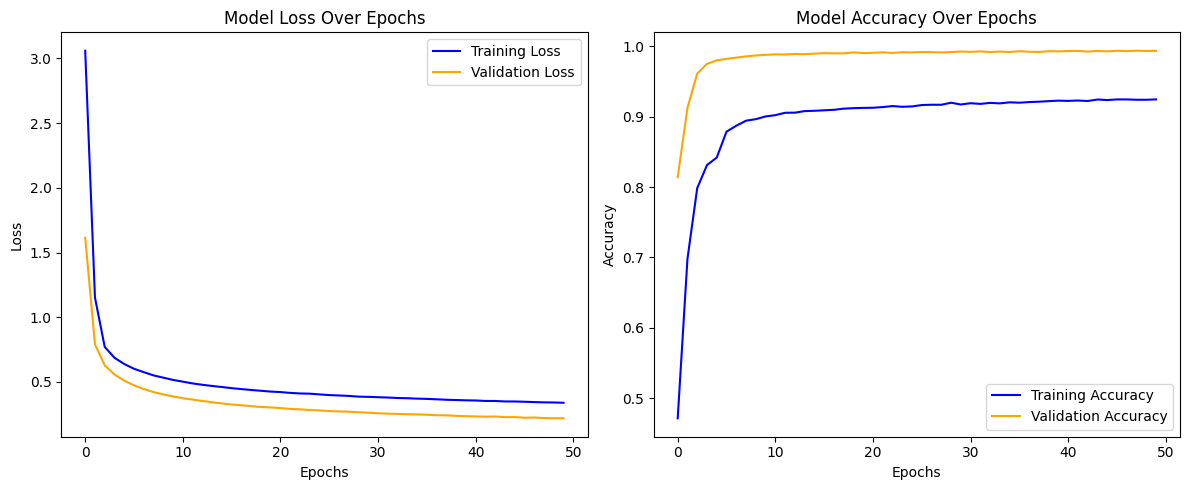

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Training Loss', color='blue')
plt.plot(history.history['val_loss'], label='Validation Loss', color='orange')
plt.title('Model Loss Over Epochs')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Training Accuracy', color='blue')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy', color='orange')
plt.title('Model Accuracy Over Epochs')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
from sklearn.metrics import classification_report

# Generate predictions
y_pred_prob = model.predict(X_test)
y_pred_classes = np.argmax(y_pred_prob, axis=1)
y_test_classes = np.argmax(y_test, axis=1)

# Generate classification report
class_names = [str(i) for i in range(num_classes)]  # Adjust based on your actual class names
report = classification_report(y_test_classes, y_pred_classes, target_names=class_names)
print(report)

KeyboardInterrupt: 

In [ ]:
# Convert the model to TensorFlow Lite format
converter = tf.lite.TFLiteConverter.from_keras_model(model)
tflite_model = converter.convert()

# Save the TensorFlow Lite model to a file
tflite_model_path = "prediction.tflite"
with open(tflite_model_path, "wb") as f:
    f.write(tflite_model)

print(f"TensorFlow Lite model saved to {tflite_model_path}")

INFO:tensorflow:Assets written to: C:\Users\vivek\AppData\Local\Temp\tmporkfg80a\assets


INFO:tensorflow:Assets written to: C:\Users\vivek\AppData\Local\Temp\tmporkfg80a\assets


In [ ]:
with open("prediction.tflite", "rb") as f:
    tflite_model = f.read()

# Convert to a C-style byte array
c_array = ', '.join(f'0x{b:02x}' for b in tflite_model)
with open("model_data.h", "w") as f:
    f.write(f"const unsigned char tflite_model[] = {{ {c_array} }};\n")
    f.write(f"const unsigned int tflite_model_len = {len(tflite_model)};")